In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

Total observations: 300


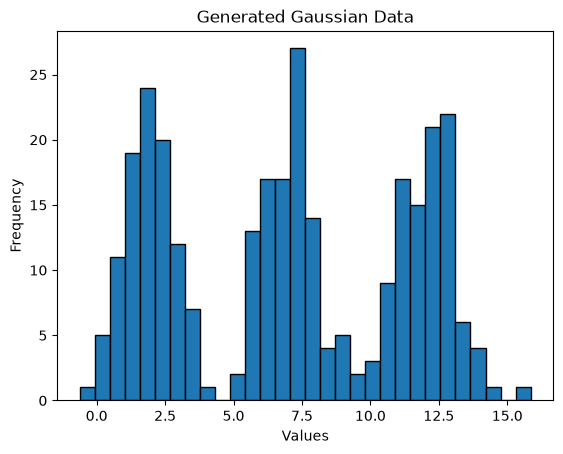

In [3]:
#-------------------------------------------------
# Question 1: Generate 300 observations from 3 groups
# -------------------------------------------------
np.random.seed(42)

group1 = np.random.normal(loc=2, scale=1, size=100)
group2 = np.random.normal(loc=7, scale=1, size=100)
group3 = np.random.normal(loc=12, scale=1, size=100)

data = np.concatenate([group1, group2, group3])
X = data.reshape(-1, 1)

print("Total observations:", len(X))

# Visualise the generated data
plt.hist(X, bins=30, edgecolor="black")
plt.title("Generated Gaussian Data")
plt.xlabel("Values")
plt.ylabel("Frequency")
plt.show()


First 20 cluster labels: [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


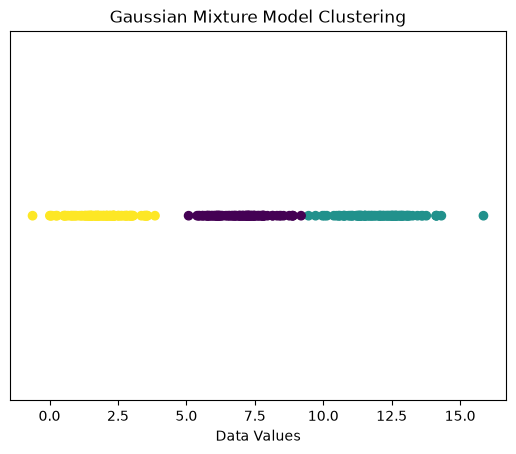

In [4]:
# -------------------------------------------------
# Question 2: Apply the EM algorithm using GMM
# -------------------------------------------------
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X)

labels = gmm.predict(X)
print("First 20 cluster labels:", labels[:20])

plt.scatter(X[:, 0], np.zeros(len(X)), c=labels, cmap="viridis")
plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Data Values")
plt.yticks([])
plt.show()

In [5]:
# -------------------------------------------------
# Question 3: Estimated parameters
# -------------------------------------------------
print("Estimated Means:")
print(gmm.means_.ravel())

print("\nEstimated Variances:")
print(gmm.covariances_.ravel())

print("\nMixing Proportions:")
print(gmm.weights_)

Estimated Means:
[ 6.98734645 12.04041718  1.89614955]

Estimated Variances:
[0.8221013  1.19793122 0.81819915]

Mixing Proportions:
[0.32957963 0.33717043 0.33324994]


Components: 1, BIC: 1733.11
Components: 2, BIC: 1655.28
Components: 3, BIC: 1526.83
Components: 4, BIC: 1545.74


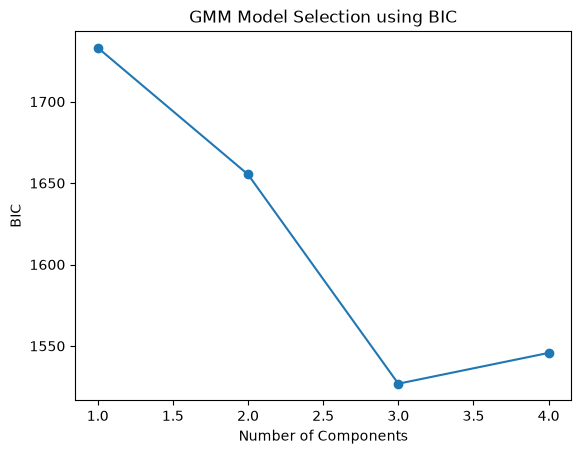

In [6]:
# -------------------------------------------------
# Question 4: BIC for 1–4 components
# -------------------------------------------------
components = [1, 2, 3, 4]
bic_values = []

for k in components:
    model = GaussianMixture(n_components=k, random_state=42)
    model.fit(X)
    bic = model.bic(X)
    bic_values.append(bic)
    print(f"Components: {k}, BIC: {bic:.2f}")

plt.plot(components, bic_values, marker="o")
plt.xlabel("Number of Components")
plt.ylabel("BIC")
plt.title("GMM Model Selection using BIC")
plt.show()

### Lab 14 assessment answers

    1. EM algorithm: An iterative maximum-likelihood method for models with latent or missing variables. It alternates between estimating latent-variable probabilities and updating parameters.
    2. Gaussian Mixture Model: A probabilistic model assuming data come from a mixture of several Gaussian distributions, each with its own mean, covariance, and mixing weight.
    3. E-step vs M-step: E-step computes the posterior probability/responsibility that each observation belongs to each component. M-step updates means, variances/covariances, and mixing weights using those responsibilities.
    4. Importance of clustering: It discovers hidden groups, supports segmentation, anomaly detection, dimensionality reduction, and exploratory analysis.
    5. Purpose of n_components: It specifies the number of mixture components/clusters to fit.
    6. Importance of BIC: BIC compares models by balancing goodness of fit against complexity. Lower BIC is generally preferred.
    7. fit() function: It trains/estimates the GMM parameters from the data using the EM algorithm.
    8. Two practical applications of GMM: Customer segmentation and image/speaker recognition; also anomaly detection and density estimation.